# Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)

**Goal:** Build a complete machine-learning project that classifies iris flowers into 3 species
using **Logistic Regression** and a **Decision Tree**, and compare them fairly.

**Steps in this notebook**
1. Import libraries
2. Load and explore the data (Pandas)
3. Exploratory Data Analysis (Seaborn graphs + pairplot)
4. Split data 80% train / 20% test (stratified, `random_state=42`)
5. Build Scikit-learn **Pipelines** (`StandardScaler` + model) so there is **no data leakage**
6. Train both models
7. Evaluate: Accuracy, Precision, Recall, F1-score
8. Confusion matrix heatmaps
9. Compare models in a results table
10. Decision Tree feature importance
11. Decision boundary visualization
12. Conclusion

All numbers and graphs below are produced by running the code. Graphs are also saved in the `results/` folder.

> **Part of the Iris Classification project.** The same pipelines are used by `train_model.py` (saves the models with joblib) and the Streamlit dashboard `app.py` in the project folder. This notebook is self-contained, so it also runs on its own in Google Colab.

## 1. Import libraries
We import everything we need once, at the top, so the rest of the notebook runs without missing names.

In [1]:
import os                      # for creating the results folder
import warnings                # to keep the output clean
import numpy as np             # numbers and arrays
import pandas as pd            # tables (DataFrames)
import matplotlib.pyplot as plt  # plotting
import seaborn as sns          # nicer statistical plots

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")      # hide non-important warnings
sns.set_theme(style="whitegrid")       # clean plot style
plt.rcParams["figure.dpi"] = 100       # sharp-enough figures

RANDOM_STATE = 42                      # fixed seed -> same results every run

# Folder where all graphs and tables will be saved.
# Inside the project (notebooks/ folder) this is ../results; in Google Colab it is ./results.
RESULTS_DIR = "../results" if os.path.basename(os.getcwd()) == "notebooks" else "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Libraries imported. Graphs will be saved in:", os.path.abspath(RESULTS_DIR))

Libraries imported. Graphs will be saved in: /home/claude/Iris_Classification/results


## 2. Load and explore the dataset
The Iris dataset has **150 flowers**, **4 measurements** (in cm) per flower, and **3 species**
(setosa, versicolor, virginica) with 50 flowers each.

In [2]:
# Load the dataset from Scikit-learn as a Pandas DataFrame (with error handling)
try:
    iris = load_iris(as_frame=True)
    df = iris.frame.copy()                       # features + 'target' column
except Exception as error:
    raise RuntimeError(f"Could not load the Iris dataset: {error}")

# Add readable species names next to the numeric target (0, 1, 2)
class_names = list(iris.target_names)            # ['setosa', 'versicolor', 'virginica']
df["species"] = df["target"].map(dict(enumerate(class_names)))

# Use shorter, cleaner column names
df.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in df.columns]
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (150, 6)


,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# Basic information about the data
print("---- Column types and missing values ----")
df.info()

print("\n---- Missing values per column ----")
print(df.isnull().sum())

print("\n---- Number of flowers per species ----")
print(df["species"].value_counts())

print("\n---- Number of duplicate rows ----")
print(df.duplicated().sum())

---- Column types and missing values ----
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB

---- Missing values per column ----
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

---- Number of flowers per species ----
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

---- Number of duplicate rows ----
1


In [4]:
# Summary statistics (mean, min, max, ...) for the 4 measurements
df[feature_names].describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


**What we learn:** there are no missing values, the 3 classes are perfectly balanced (50 each),
and the four features are on slightly different scales - a good reason to use `StandardScaler`.

**Data-quality note:** the original Iris data contains one duplicated flower (two identical rows of virginica). It is kept so results stay comparable with other Iris benchmarks. With `random_state=42` both copies fall into the training set, so no identical flower appears in both train and test (no leakage).

## 3. Exploratory Data Analysis (EDA)
Graphs help us see which features separate the species best *before* we train any model.

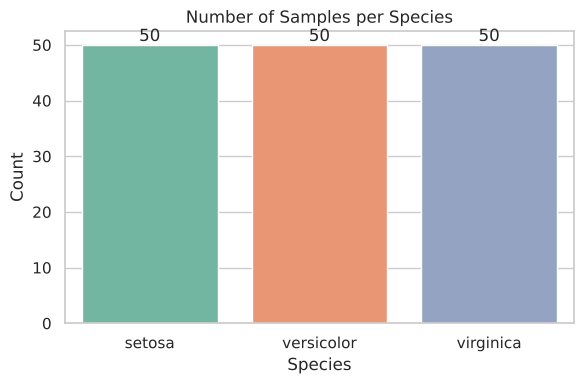

In [5]:
# 3.1 Class distribution - are the classes balanced?
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="species", hue="species", palette="Set2", legend=False)
for container in ax.containers:
    ax.bar_label(container)                       # show the count on top of each bar
plt.title("Number of Samples per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

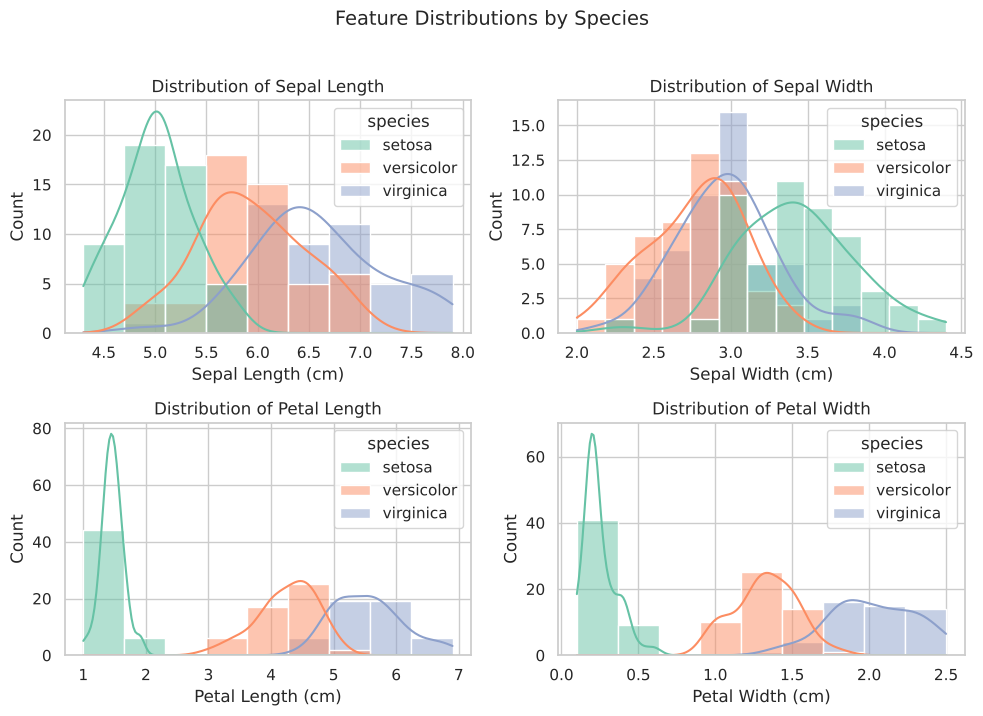

In [6]:
# 3.2 Histograms of each feature, coloured by species
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.ravel(), feature_names):
    sns.histplot(data=df, x=feature, hue="species", kde=True, palette="Set2", ax=ax)
    ax.set_title(f"Distribution of {feature.replace('_', ' ').title()}")
    ax.set_xlabel(feature.replace("_", " ").title() + " (cm)")
    ax.set_ylabel("Count")
plt.suptitle("Feature Distributions by Species", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/02_feature_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

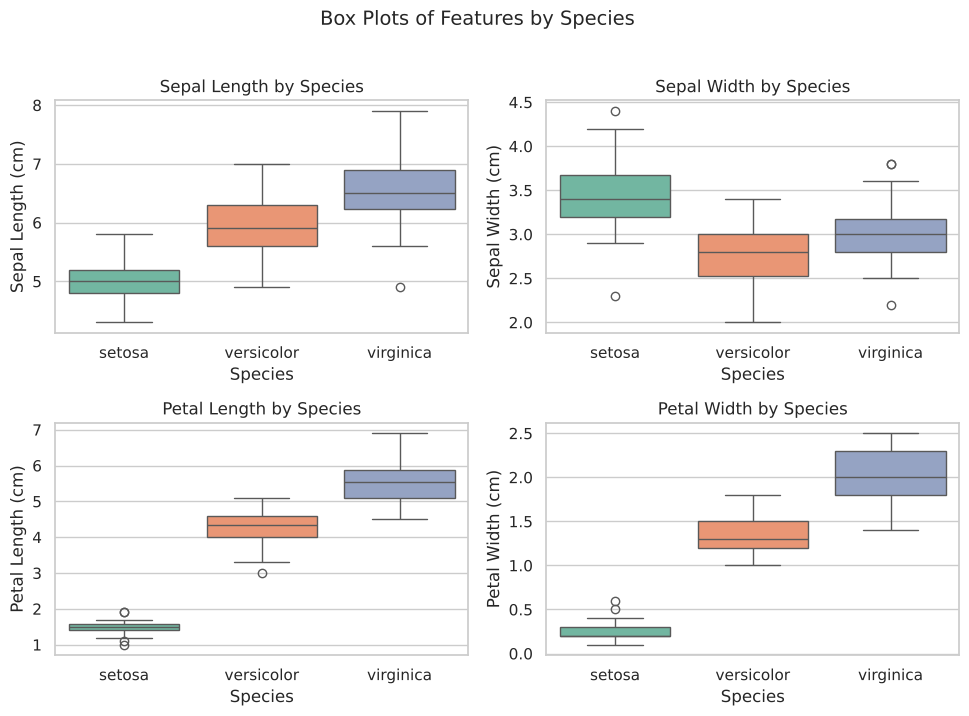

In [7]:
# 3.3 Box plots - show the spread and outliers of each feature per species
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.ravel(), feature_names):
    sns.boxplot(data=df, x="species", y=feature, hue="species", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature.replace("_", " ").title() + " (cm)")
plt.suptitle("Box Plots of Features by Species", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/03_feature_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

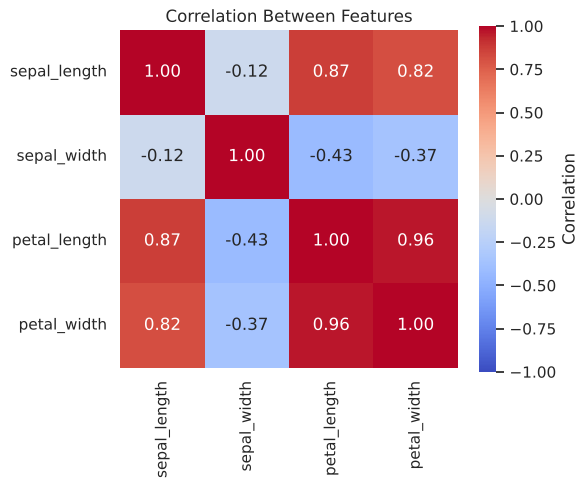

In [8]:
# 3.4 Correlation heatmap - how strongly are features related to each other?
plt.figure(figsize=(6, 5))
sns.heatmap(df[feature_names].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Correlation"})
plt.title("Correlation Between Features")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

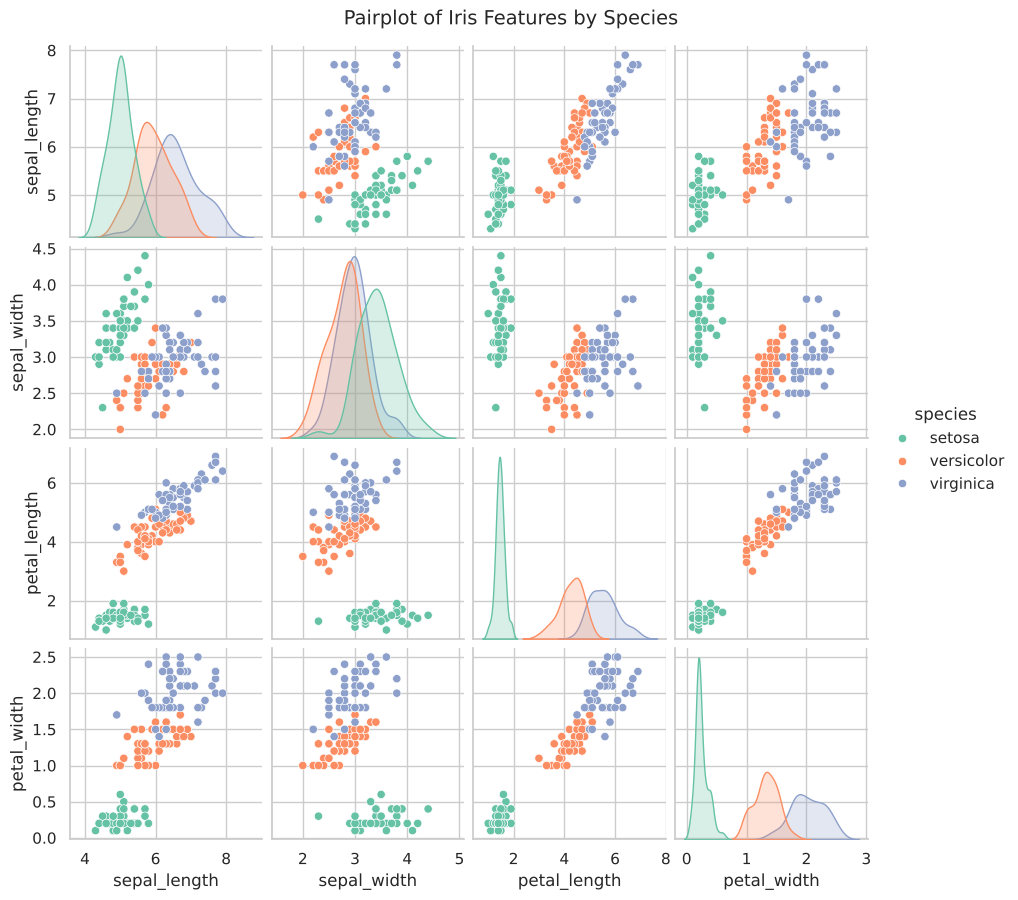

In [9]:
# 3.5 Pairplot - every feature plotted against every other feature
pair = sns.pairplot(df[feature_names + ["species"]], hue="species",
                    palette="Set2", diag_kind="kde", height=2.2)
pair.fig.suptitle("Pairplot of Iris Features by Species", y=1.02, fontsize=14)
pair.savefig(f"{RESULTS_DIR}/05_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

**EDA findings (what the graphs show):**
- **Setosa** is clearly separated from the other two species, especially by petal length and petal width.
- **Versicolor** and **virginica** overlap a little, so they are the pair a model can confuse.
- **Petal length** and **petal width** are strongly correlated with each other and separate the species best.

## 4. Train / test split (80% / 20%)
- `test_size=0.2` -> 80% training, 20% testing
- `random_state=42` -> same split every time
- `stratify=y` -> each species appears in the **same proportion** in train and test sets

In [10]:
X = df[feature_names]          # input features (4 columns)
y = df["target"]               # labels: 0 = setosa, 1 = versicolor, 2 = virginica

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("\nClass counts in training set:\n", y_train.map(dict(enumerate(class_names))).value_counts().to_string())
print("\nClass counts in test set:\n", y_test.map(dict(enumerate(class_names))).value_counts().to_string())

Training set: (120, 4) | Test set: (30, 4)

Class counts in training set:
 target
setosa        40
virginica     40
versicolor    40

Class counts in test set:
 target
setosa        10
virginica     10
versicolor    10


## 5. Build pipelines (scaling without data leakage)

**What is data leakage?** If we scale the *whole* dataset before splitting, the scaler "sees" the test data
(its mean and standard deviation), which is cheating.

**The fix:** a Scikit-learn `Pipeline` chains the scaler and the model. When we call `.fit()` on the training data,
the scaler learns its mean/std **from the training data only**, and then simply applies them to the test data.

- **Logistic Regression** needs scaled features, so it uses `StandardScaler` + model.
- **Decision Tree** does not really need scaling (trees only compare thresholds), but we use the **same pipeline structure**
  so both models get identical preprocessing and the comparison is fair. Scaling does not change the tree's predictions.
  We limit `max_depth=3` to keep the tree small, easy to explain, and less likely to overfit.

In [11]:
# Pipeline 1: StandardScaler -> Logistic Regression
logreg_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

# Pipeline 2: StandardScaler -> Decision Tree
tree_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
])

models = {
    "Logistic Regression": logreg_pipeline,
    "Decision Tree": tree_pipeline,
}
print("Pipelines created:", list(models.keys()))

Pipelines created: ['Logistic Regression', 'Decision Tree']


## 6. Train both models
`.fit(X_train, y_train)` trains the pipeline: the scaler learns from the training data, then the model is trained on the scaled data.

In [12]:
for name, pipeline in models.items():
    try:
        pipeline.fit(X_train, y_train)          # scaler + model are fitted on TRAINING data only
        print(f"{name}: trained successfully")
    except Exception as error:
        raise RuntimeError(f"Training failed for {name}: {error}")

# Predict the species of the unseen test flowers
predictions = {name: pipeline.predict(X_test) for name, pipeline in models.items()}

Logistic Regression: trained successfully
Decision Tree: trained successfully


## 7. Evaluate the models
For a 3-class problem we must choose how to average Precision, Recall and F1 across classes. We use **macro** averaging:
the score is calculated for each class and then averaged, treating every class equally (right choice here because the classes are balanced).

- **Accuracy** = correct predictions / all predictions
- **Precision** = of the flowers predicted as a class, how many really were that class
- **Recall** = of the flowers that really were a class, how many we found
- **F1-score** = the balance (harmonic mean) of precision and recall

In [13]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)":  f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [14]:
# Detailed per-class report for each model
for name, y_pred in predictions.items():
    print("=" * 60)
    print(f"Classification report - {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3, zero_division=0))

Classification report - Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Classification report - Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



## 8. Confusion matrix heatmaps
Each row is the **true** species and each column is the **predicted** species.
Numbers on the diagonal are correct predictions; numbers off the diagonal are mistakes.

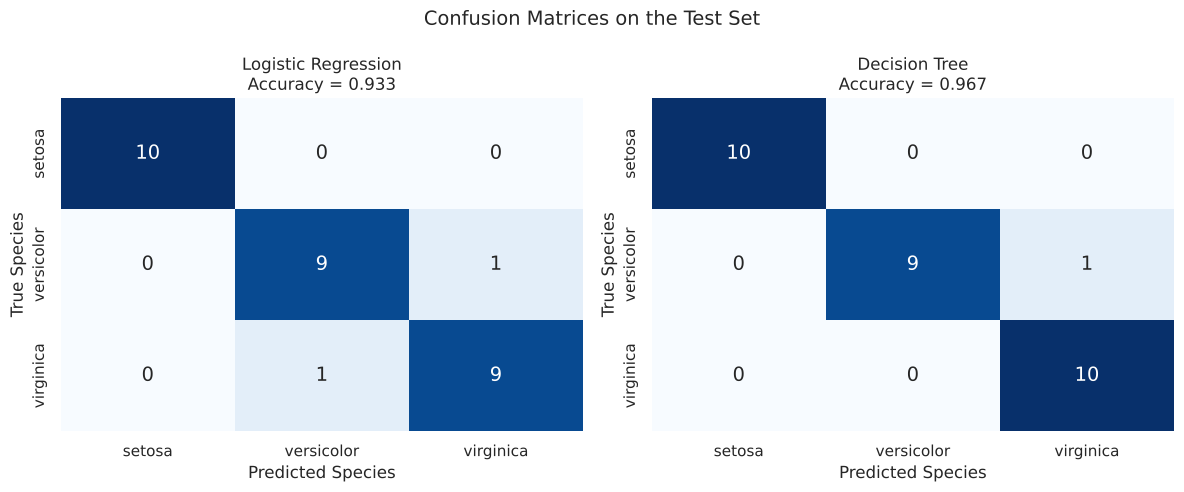

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax,
                annot_kws={"size": 14})
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f"{name}\nAccuracy = {acc:.3f}")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("True Species")
plt.suptitle("Confusion Matrices on the Test Set", fontsize=14)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/06_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Also save each confusion matrix as its own image (handy for reports)
for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax,
                cbar_kws={"label": "Number of flowers"}, annot_kws={"size": 14})
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("True Species")
    plt.tight_layout()
    filename = name.lower().replace(" ", "_")
    plt.savefig(f"{RESULTS_DIR}/06_confusion_matrix_{filename}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
print("Individual confusion matrix images saved.")

Individual confusion matrix images saved.


In [17]:
# Print exactly which test flowers were misclassified (if any)
for name, y_pred in predictions.items():
    wrong = X_test[y_pred != y_test].copy()
    wrong["true_species"] = y_test[y_pred != y_test].map(dict(enumerate(class_names)))
    wrong["predicted_species"] = pd.Series(y_pred, index=X_test.index)[y_pred != y_test].map(dict(enumerate(class_names)))
    print(f"\n{name}: {len(wrong)} misclassified test flower(s)")
    if len(wrong):
        display(wrong)


Logistic Regression: 2 misclassified test flower(s)


,sepal_length,sepal_width,petal_length,petal_width,true_species,predicted_species
134,6.1,2.6,5.6,1.4,virginica,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica



Decision Tree: 1 misclassified test flower(s)


,sepal_length,sepal_width,petal_length,petal_width,true_species,predicted_species
77,6.7,3.0,5.0,1.7,versicolor,virginica


## 9. Model comparison
We put all metrics side by side and pick the better model **from the real test results above** (not assumed in advance).

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


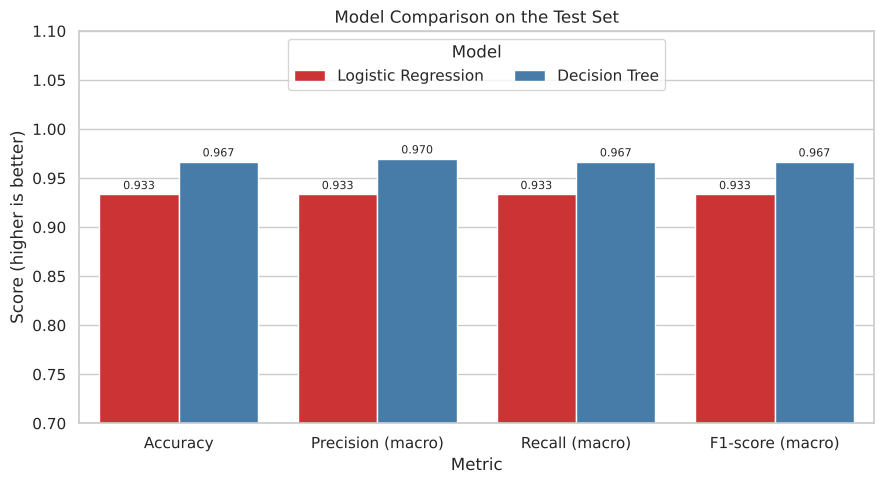

In [18]:
comparison = results.copy()
comparison.round(4).to_csv(f"{RESULTS_DIR}/model_comparison.csv")      # save the table
display(comparison.round(4))

# Grouped bar chart of the four metrics
plot_df = comparison.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set1")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.ylim(0.7, 1.1)
plt.title("Model Comparison on the Test Set")
plt.xlabel("Metric")
plt.ylabel("Score (higher is better)")
plt.legend(title="Model", loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/07_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Decide the winner automatically from the results (primary: F1-score, tie-breaker: accuracy)
ranked = comparison.sort_values(["F1-score (macro)", "Accuracy"], ascending=False)
best_name = ranked.index[0]
top, second = ranked.iloc[0], ranked.iloc[1]

if np.isclose(top["F1-score (macro)"], second["F1-score (macro)"]) and np.isclose(top["Accuracy"], second["Accuracy"]):
    print("RESULT: Both models performed the same on this test set (a tie).")
else:
    print(f"RESULT: The better model on this test set is: {best_name}")
    print(f"  Accuracy : {top['Accuracy']:.4f}  vs  {second['Accuracy']:.4f}")
    print(f"  F1-score : {top['F1-score (macro)']:.4f}  vs  {second['F1-score (macro)']:.4f}")

n_test = len(y_test)
print(f"\nNote: the test set has only {n_test} flowers, so one extra mistake changes accuracy by about {100/n_test:.1f} percentage points.")

RESULT: The better model on this test set is: Decision Tree
  Accuracy : 0.9667  vs  0.9333
  F1-score : 0.9666  vs  0.9333

Note: the test set has only 30 flowers, so one extra mistake changes accuracy by about 3.3 percentage points.


### Is the difference reliable? (5-fold cross-validation check)
Because the test set is small, we double-check with **stratified 5-fold cross-validation** on the full data.
Using a Pipeline inside cross-validation means the scaler is re-fitted inside each fold, so there is still no leakage.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    cv_rows.append({"Model": name,
                    "CV mean accuracy": scores["test_accuracy"].mean(),
                    "CV std accuracy": scores["test_accuracy"].std(),
                    "CV mean F1 (macro)": scores["test_f1_macro"].mean()})

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4).to_csv(f"{RESULTS_DIR}/cross_validation_results.csv")
cv_results.round(4)

,CV mean accuracy,CV std accuracy,CV mean F1 (macro)
Model,,,
Logistic Regression,0.9533,0.0452,0.9532
Decision Tree,0.9600,0.0249,0.9598


## 10. Decision Tree feature importance
Feature importance shows how much each feature helped the tree make its decisions (values add up to 1).
This only applies to the Decision Tree (Logistic Regression has coefficients instead).

petal_length    0.5791
petal_width     0.4209
sepal_width     0.0000
sepal_length    0.0000


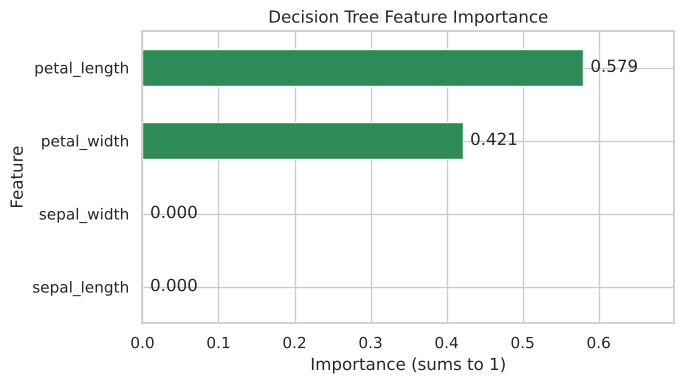

In [21]:
tree_model = tree_pipeline.named_steps["model"]          # take the tree out of the pipeline

importance = pd.Series(tree_model.feature_importances_, index=feature_names).sort_values(ascending=True)
print(importance.sort_values(ascending=False).round(4).to_string())

plt.figure(figsize=(7, 4))
ax = importance.plot(kind="barh", color="seagreen")
for i, v in enumerate(importance.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance (sums to 1)")
plt.ylabel("Feature")
plt.xlim(0, max(importance.values) + 0.12)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/08_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

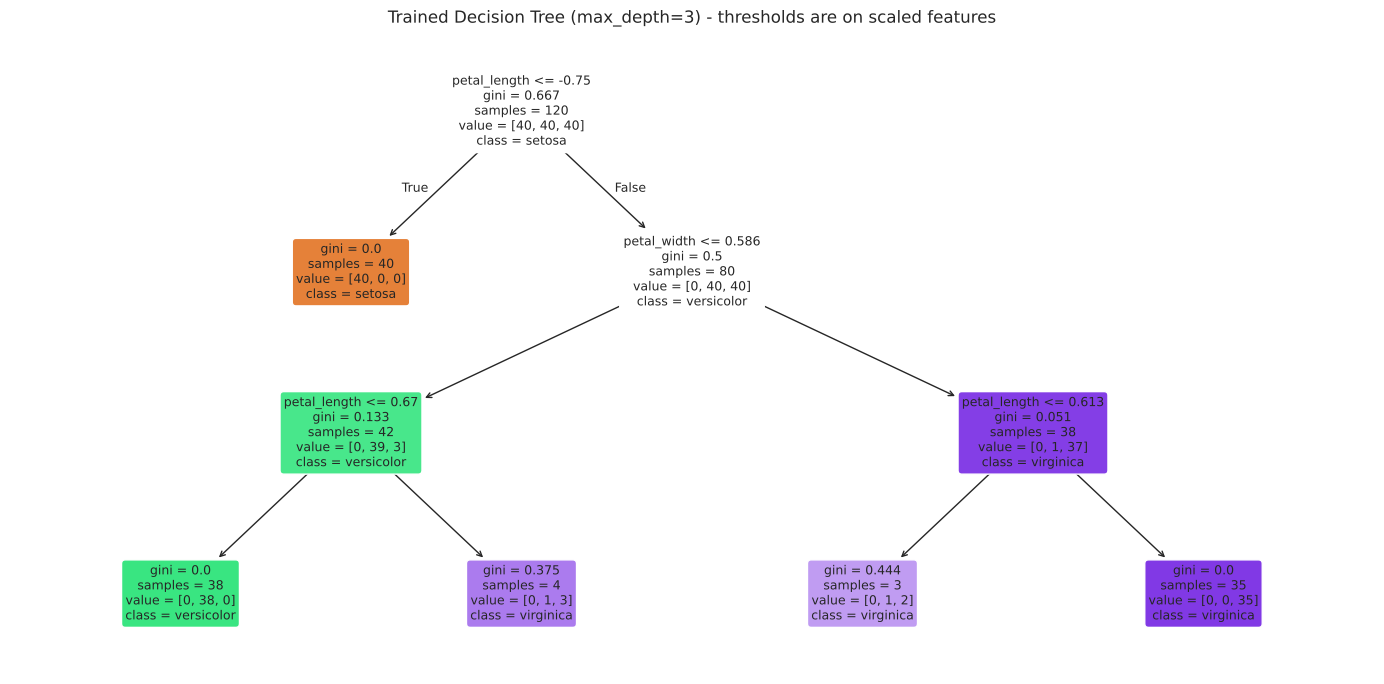

In [22]:
# Draw the trained tree itself so we can read its rules
# (the tree was trained on scaled values, so thresholds are in "standard deviations from the mean")
plt.figure(figsize=(14, 7))
plot_tree(tree_model, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=9)
plt.title("Trained Decision Tree (max_depth=3) - thresholds are on scaled features")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/09_decision_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Decision boundary visualization
**What is a decision boundary?** Imagine the flower measurements as points on a map. A trained model colours every spot on the map
with the species it would predict there. The lines where the colour changes are the **decision boundaries**.

**How we draw it:** we can only draw 2 dimensions, so we train **two extra pipelines** that use just the two most useful
features: **petal length** and **petal width** (the best separators seen in the EDA).
They use the same split and the same `StandardScaler` + model structure. The coloured regions are the model's predictions;
the dots are the real flowers (circles = training data, squares = test data).

*These 2-feature models are only for the picture. The main results above use all 4 features.*

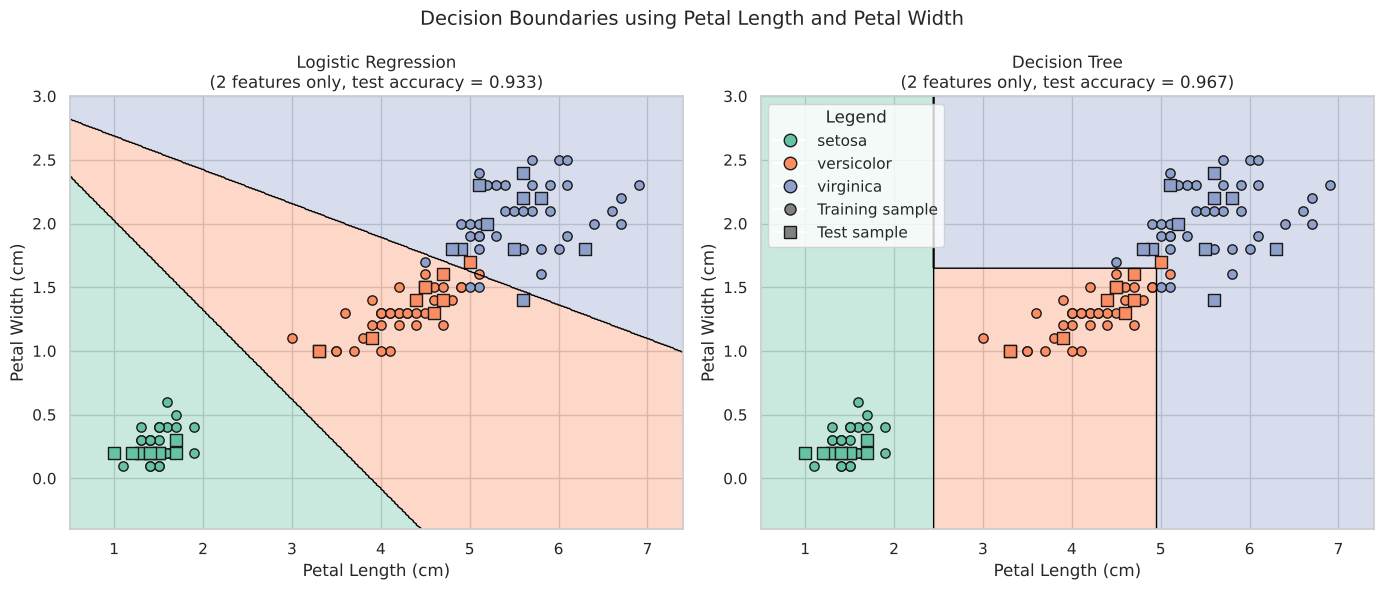

In [23]:
# Choose two features for the 2D picture
plot_features = ["petal_length", "petal_width"]
X_train_2d, X_test_2d = X_train[plot_features], X_test[plot_features]

# Same pipeline structure, trained on only the 2 chosen features
boundary_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("scaler", StandardScaler()),
                               ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]),
}
for pipe in boundary_models.values():
    pipe.fit(X_train_2d, y_train)

# Build a fine grid of points covering the whole plot area
x_min, x_max = X[plot_features[0]].min() - 0.5, X[plot_features[0]].max() + 0.5
y_min, y_max = X[plot_features[1]].min() - 0.5, X[plot_features[1]].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=plot_features)

colors = ["#66c2a5", "#fc8d62", "#8da0cb"]            # one colour per species
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
cmap_regions = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pipe) in zip(axes, boundary_models.items()):
    Z = pipe.predict(grid).reshape(xx.shape)           # predict a species for every grid point
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.35)   # coloured regions
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors="black", linewidths=1)             # boundary lines

    for k, cls in enumerate(class_names):               # training points = circles
        m = y_train == k
        ax.scatter(X_train_2d[m][plot_features[0]], X_train_2d[m][plot_features[1]],
                   c=colors[k], edgecolor="k", s=45, marker="o")
    for k, cls in enumerate(class_names):               # test points = squares
        m = y_test == k
        ax.scatter(X_test_2d[m][plot_features[0]], X_test_2d[m][plot_features[1]],
                   c=colors[k], edgecolor="k", s=70, marker="s")

    test_acc_2d = accuracy_score(y_test, pipe.predict(X_test_2d))
    ax.set_title(f"{name}\n(2 features only, test accuracy = {test_acc_2d:.3f})")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

# One shared legend
legend_items = [Line2D([0], [0], marker="o", color="w", markerfacecolor=colors[k], markeredgecolor="k",
                       markersize=9, label=class_names[k]) for k in range(3)]
legend_items += [Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markeredgecolor="k", markersize=8, label="Training sample"),
                 Line2D([0], [0], marker="s", color="w", markerfacecolor="grey", markeredgecolor="k", markersize=9, label="Test sample")]
axes[1].legend(handles=legend_items, title="Legend", loc="upper left")

plt.suptitle("Decision Boundaries using Petal Length and Petal Width", fontsize=14)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/10_decision_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read the decision boundary plot**
- Each background colour is the species the model predicts for that petal length/width.
- **Logistic Regression** draws smooth, **straight-line** boundaries.
- The **Decision Tree** draws **box-shaped (axis-aligned)** boundaries, because every tree rule is of the form "feature <= threshold".
- Points sitting in the wrong colour are misclassified. Any such points are around the border between **versicolor** and **virginica**,
  where the species overlap, while **setosa** is far away from the others.

## 12. Final summary
The cell below prints the final conclusion directly from the computed results, so it always matches what was actually run.

In [24]:
print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
print(f"Dataset        : Iris ({df.shape[0]} samples, {len(feature_names)} features, {len(class_names)} classes)")
print(f"Split          : {len(X_train)} train / {len(X_test)} test (stratified, random_state={RANDOM_STATE})")
print("Preprocessing  : StandardScaler inside a Pipeline (no data leakage)\n")
print(comparison.round(4).to_string())
print()
print("Cross-validated accuracy (5-fold):")
print(cv_results.round(4).to_string())
print()
print("Most important Decision Tree feature:", importance.idxmax(), f"({importance.max():.3f})")
if np.isclose(top["F1-score (macro)"], second["F1-score (macro)"]) and np.isclose(top["Accuracy"], second["Accuracy"]):
    print("Better model on the test set: tie - both models performed equally.")
else:
    print("Better model on the test set:", best_name)
print("\nAll graphs and tables were saved in the 'results/' folder:")
for f in sorted(os.listdir(RESULTS_DIR)):
    print("  -", f)

FINAL SUMMARY
Dataset        : Iris (150 samples, 4 features, 3 classes)
Split          : 120 train / 30 test (stratified, random_state=42)
Preprocessing  : StandardScaler inside a Pipeline (no data leakage)

                     Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
Model                                                                             
Logistic Regression    0.9333             0.9333          0.9333            0.9333
Decision Tree          0.9667             0.9697          0.9667            0.9666

Cross-validated accuracy (5-fold):
                     CV mean accuracy  CV std accuracy  CV mean F1 (macro)
Model                                                                     
Logistic Regression            0.9533           0.0452              0.9532
Decision Tree                  0.9600           0.0249              0.9598

Most important Decision Tree feature: petal_length (0.579)
Better model on the test set: Decision Tree

All graphs and tab